# EDA: International Airline Passengers

Monthly number of international airline passengers (in thousands), January 1949 – December 1960.

## 1. Goal

- Understand the parts of the time series: trend, seasonality, noise
- Check if the series is stationary
- Find out which transformations we need before modeling
- Make conclusions to help choose a forecasting model

## 2. Load the data

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("andreazzini/international-airline-passengers")

print("Path to dataset files:", path)

/Users/a.yeustsihneyeu@godeltech.com/Projects/airplane-passengers/.airplane/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/a.yeustsihneyeu@godeltech.com/Projects/airplane-passengers/.airplane/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/a.yeustsihneyeu@godeltech.com/.cache/kagglehub/datasets/andreazzini/international-airline-passengers/versions/1


In [2]:
import os
import numpy as np
import pandas as pd

# Path to the CSV file inside the downloaded folder
csv_path = os.path.join(path, "international-airline-passengers.csv")

# Read the file
df = pd.read_csv(csv_path)

# The original column names are long, so rename them
df.columns = ["month", "passengers"]

# The last line of the file is a text note, not data.
# It has no passengers value, so we drop rows with missing values.
df = df.dropna()

# Convert types: month -> datetime, passengers -> int
df["month"] = pd.to_datetime(df["month"])
df["passengers"] = df["passengers"].astype(int)

# Use month as the index (standard for time series)
df = df.set_index("month")

## 3. Data overview

- Shape, data types, first and last rows
- Missing values and duplicates
- Time index: frequency, missing months
- Basic statistics

In [3]:
# Shape: (rows, columns)
print("Shape:", df.shape)

# Column types and non-null counts
df.info()

Shape: (144, 1)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB


In [4]:
# First rows
df.head()

,passengers
month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [5]:
# Last rows
df.tail()

,passengers
month,
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390
1960-12-01,432


In [6]:
# Missing values in each column
print("Missing values:")
print(df.isna().sum())

# Duplicated dates in the index (each month should appear only once)
print("Duplicated dates:", df.index.duplicated().sum())

Missing values:
passengers    0
dtype: int64
Duplicated dates: 0


In [7]:
# Time range of the data
print("Start:", df.index.min().date())
print("End:", df.index.max().date())

# Guess the frequency of the index ("MS" = month start)
print("Frequency:", pd.infer_freq(df.index))

# Build a full list of months and check which ones are missing
full_range = pd.date_range(df.index.min(), df.index.max(), freq="MS")
missing_months = full_range.difference(df.index)
print("Missing months:", len(missing_months))

Start: 1949-01-01
End: 1960-12-01
Frequency: MS
Missing months: 0


In [8]:
# Basic statistics: count, mean, std, min, quartiles, max
df.describe()

,passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


## 4. Time series plot

Line plot of passengers over time: general shape, trend, seasonal ups and downs, outliers.

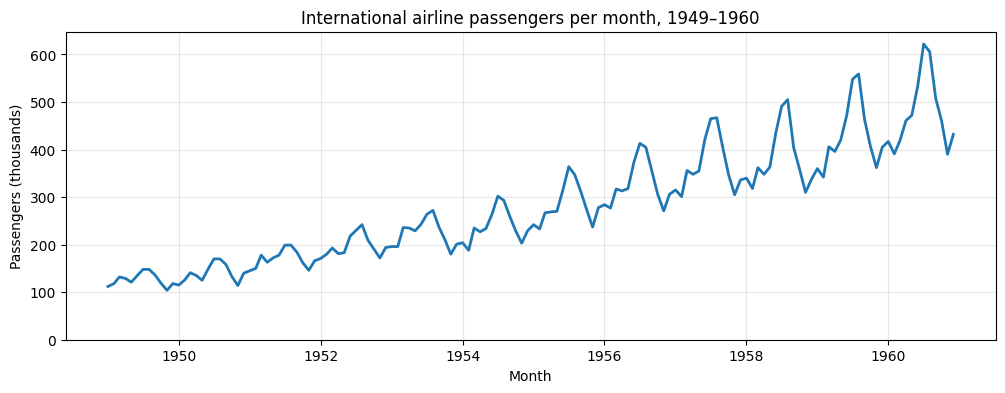

In [9]:
import matplotlib.pyplot as plt

# One line plot of the whole series
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df["passengers"], linewidth=2)

# Titles and axis labels
ax.set_title("International airline passengers per month, 1949–1960")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers (thousands)")

# Light grid to make values easier to read
ax.grid(alpha=0.3)

# Start the y axis from 0 so the growth is not exaggerated
ax.set_ylim(bottom=0)

plt.show()

## 5. Trend

**What is a trend?**
A trend is the long-term direction of the series: is it going up, going down, or staying flat?
It ignores short ups and downs (like the summer peaks we saw in section 4).

**How do we see it? Rolling mean (moving average)**
For each month we take the average of the 12 months around it.
We use a window of 12 because the seasonal pattern repeats every 12 months.
An average over one full year contains every month once, so the seasonal ups and downs cancel out
and only the trend is left.

**Rolling standard deviation**
In the same 12-month window we also compute the standard deviation.
It shows how big the ups and downs are in each part of the series.

**Why do we need this?**
- To see the shape of the trend: straight line, or growing faster over time?
- To check if the mean and the spread change over time.
  If they do, the series is **not stationary** (we will test this properly in section 9).
- If the spread grows together with the level, the seasonal swings are **proportional to the level**.
  This hints at a multiplicative model (section 7) and a log transformation (section 8).

**Notes**
- `center=True` puts the average in the middle of the window, so the line does not lag behind the data.
- The first and the last few values are empty (NaN): the window is not full there.

In [10]:
# 12-month window, because the season repeats every 12 months
window = 12

# Rolling mean = trend without the seasonal ups and downs
rolling_mean = df["passengers"].rolling(window=window, center=True).mean()

# Rolling std = how big the ups and downs are in each window
rolling_std = df["passengers"].rolling(window=window, center=True).std()

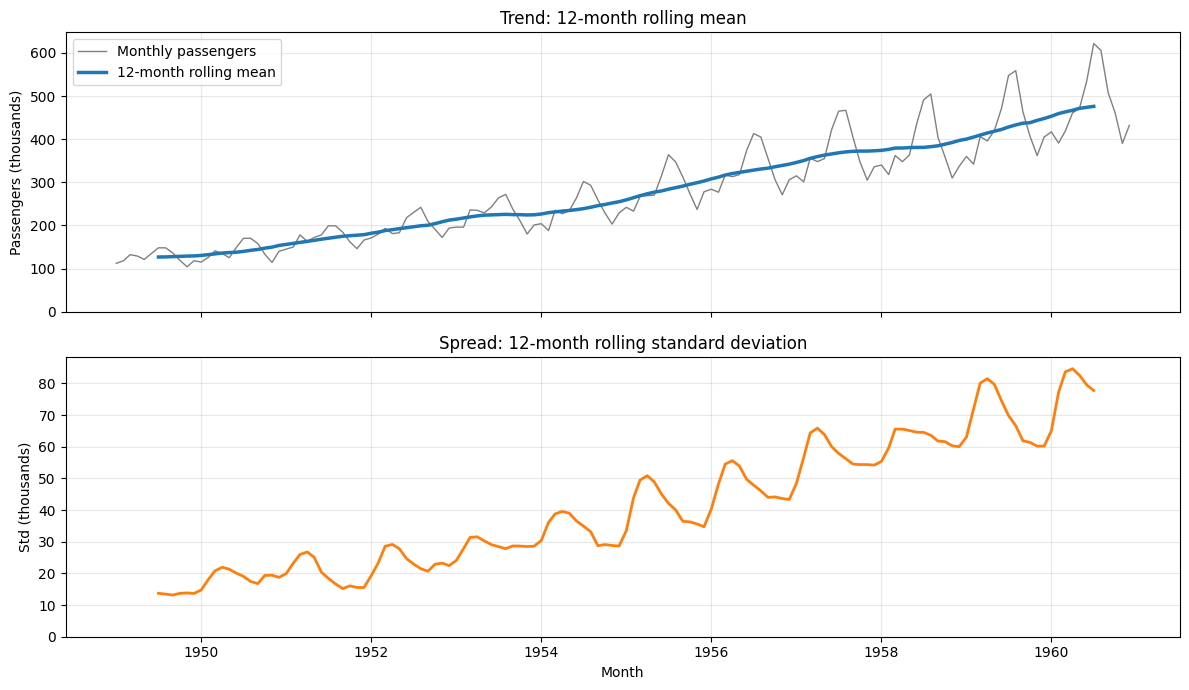

In [11]:
# Two plots, one under the other, with the same time axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Top: original series (thin, gray) and the trend (thick, colored)
ax1.plot(df.index, df["passengers"], color="gray", linewidth=1, label="Monthly passengers")
ax1.plot(rolling_mean.index, rolling_mean, color="tab:blue", linewidth=2.5, label="12-month rolling mean")
ax1.set_title("Trend: 12-month rolling mean")
ax1.set_ylabel("Passengers (thousands)")
ax1.set_ylim(bottom=0)
ax1.grid(alpha=0.3)
ax1.legend()

# Bottom: rolling std (the size of the ups and downs)
ax2.plot(rolling_std.index, rolling_std, color="tab:orange", linewidth=2)
ax2.set_title("Spread: 12-month rolling standard deviation")
ax2.set_xlabel("Month")
ax2.set_ylabel("Std (thousands)")
ax2.set_ylim(bottom=0)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# The same idea in numbers: mean and std for each year
yearly = df["passengers"].groupby(df.index.year).agg(["mean", "std"])

# std / mean: if it stays about the same,
# the swings grow in proportion to the level
yearly["std_to_mean"] = yearly["std"] / yearly["mean"]

yearly.round(2)

,mean,std,std_to_mean
month,,,
1949,126.67,13.72,0.11
1950,139.67,19.07,0.14
1951,170.17,18.44,0.11
1952,197.00,22.97,0.12
1953,225.00,28.47,0.13
1954,238.92,34.92,0.15
1955,284.00,42.14,0.15
1956,328.25,47.86,0.15
1957,368.42,57.89,0.16


## 6. Seasonality

- Seasonal plot: one line per year, months on the X axis
- Boxplot by month
- Yearly totals

In [13]:
import calendar

# Short month names for the X axis: Jan, Feb, ...
month_names = list(calendar.month_abbr)[1:]

# Table: rows = months (1..12), columns = years, values = passengers
seasonal_table = df.pivot_table(
    index=df.index.month,
    columns=df.index.year,
    values="passengers",
)

seasonal_table

month,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
1,112.0,115.0,145.0,171.0,196.0,204.0,242.0,284.0,315.0,340.0,360.0,417.0
2,118.0,126.0,150.0,180.0,196.0,188.0,233.0,277.0,301.0,318.0,342.0,391.0
3,132.0,141.0,178.0,193.0,236.0,235.0,267.0,317.0,356.0,362.0,406.0,419.0
4,129.0,135.0,163.0,181.0,235.0,227.0,269.0,313.0,348.0,348.0,396.0,461.0
5,121.0,125.0,172.0,183.0,229.0,234.0,270.0,318.0,355.0,363.0,420.0,472.0
6,135.0,149.0,178.0,218.0,243.0,264.0,315.0,374.0,422.0,435.0,472.0,535.0
7,148.0,170.0,199.0,230.0,264.0,302.0,364.0,413.0,465.0,491.0,548.0,622.0
8,148.0,170.0,199.0,242.0,272.0,293.0,347.0,405.0,467.0,505.0,559.0,606.0
9,136.0,158.0,184.0,209.0,237.0,259.0,312.0,355.0,404.0,404.0,463.0,508.0


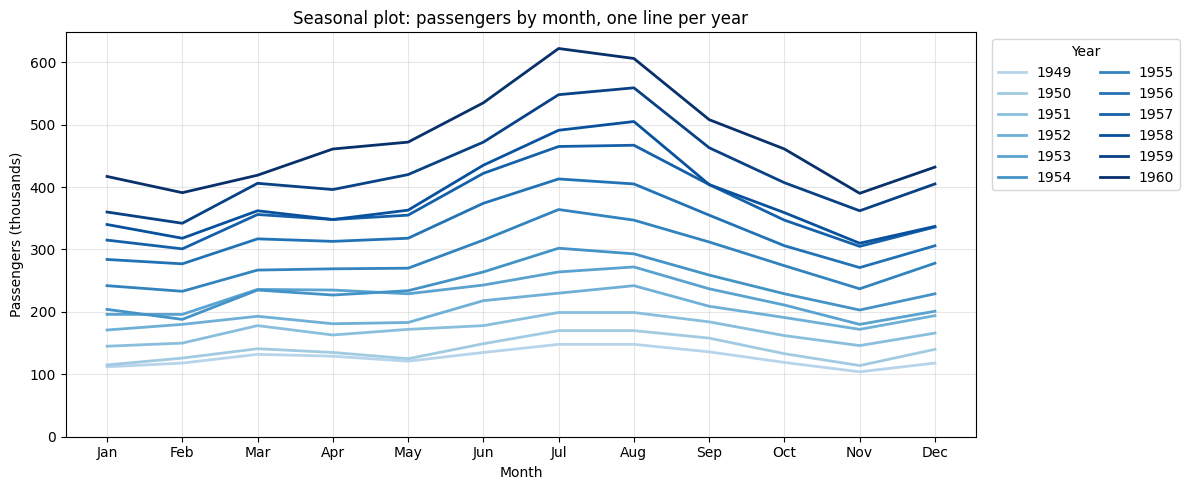

In [14]:
# Seasonal plot: one line per year, months on the X axis
fig, ax = plt.subplots(figsize=(12, 5))

# Years are ordered, so we use one color from light (old) to dark (new)
colors = plt.cm.Blues(np.linspace(0.3, 1, len(seasonal_table.columns)))

for year, color in zip(seasonal_table.columns, colors):
    ax.plot(seasonal_table.index, seasonal_table[year], color=color, linewidth=2, label=year)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_title("Seasonal plot: passengers by month, one line per year")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers (thousands)")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
ax.legend(title="Year", ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left")

plt.tight_layout()
plt.show()

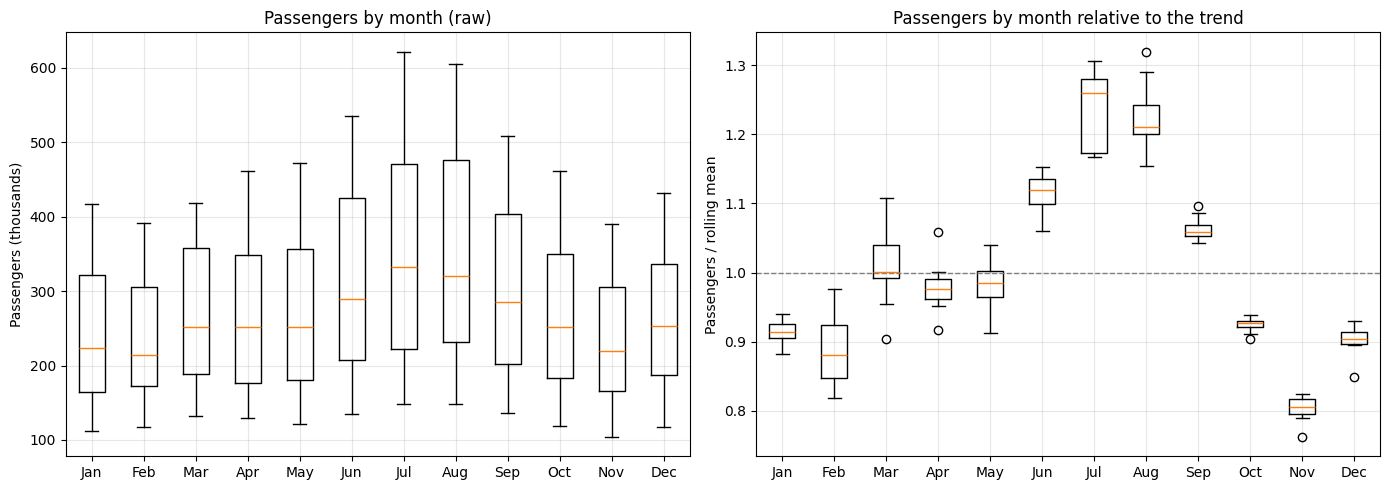

In [15]:
# Seasonal ratio: each month divided by the trend from section 5.
# 1.2 means "20% above the trend", 0.9 means "10% below the trend".
# This removes the growth, so we compare months fairly across years.
seasonal_ratio = df["passengers"] / rolling_mean

# Group values by month number (1..12)
raw_by_month = [df["passengers"][df.index.month == m] for m in range(1, 13)]
ratio_by_month = [seasonal_ratio[seasonal_ratio.index.month == m].dropna() for m in range(1, 13)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: raw values (boxes are wide because they also contain the trend)
ax1.boxplot(raw_by_month)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(month_names)
ax1.set_title("Passengers by month (raw)")
ax1.set_ylabel("Passengers (thousands)")
ax1.grid(alpha=0.3)

# Right: values relative to the trend (only the seasonal effect is left)
ax2.boxplot(ratio_by_month)
ax2.axhline(1, color="gray", linestyle="--", linewidth=1)  # 1 = exactly on the trend
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(month_names)
ax2.set_title("Passengers by month relative to the trend")
ax2.set_ylabel("Passengers / rolling mean")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# Average seasonal ratio for each month (sorted from the strongest month)
month_effect = seasonal_ratio.groupby(seasonal_ratio.index.month).mean()
month_effect.index = month_names

month_effect.sort_values(ascending=False).round(2)

Jul    1.24
Aug    1.22
Jun    1.12
Sep    1.06
Mar    1.01
May    0.98
Apr    0.98
Oct    0.92
Jan    0.91
Dec    0.90
Feb    0.89
Nov    0.80
Name: passengers, dtype: float64

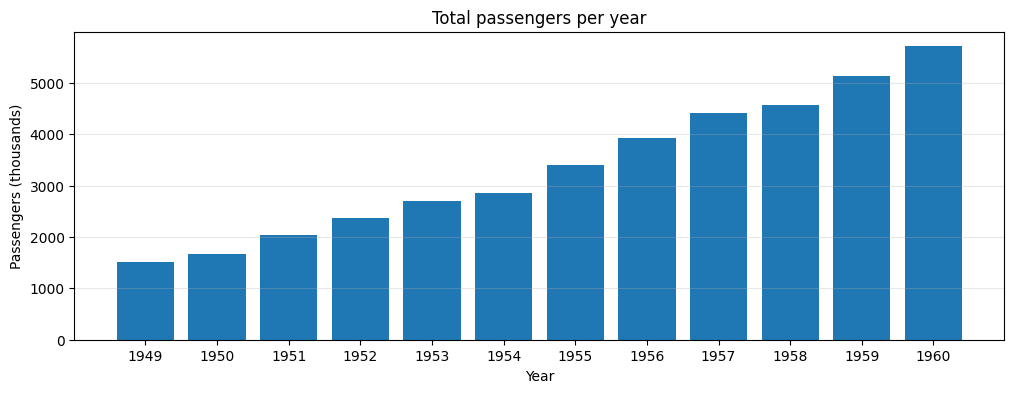

month
1949     NaN
1950    10.3
1951    21.8
1952    15.8
1953    14.2
1954     6.2
1955    18.9
1956    15.6
1957    12.2
1958     3.4
1959    12.4
1960    11.2
Name: passengers, dtype: float64

In [17]:
# Total passengers per year
yearly_total = df["passengers"].groupby(df.index.year).sum()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(yearly_total.index, yearly_total, color="tab:blue")
ax.set_title("Total passengers per year")
ax.set_xlabel("Year")
ax.set_ylabel("Passengers (thousands)")
ax.set_xticks(yearly_total.index)
ax.grid(axis="y", alpha=0.3)

plt.show()

# Growth compared to the previous year, in %
(yearly_total.pct_change() * 100).round(1)

## 7. Decomposition

Split the series into trend, seasonality and residuals. Compare additive and multiplicative models.

In [18]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Additive model: passengers = trend + seasonal + residual
# (seasonal swings have the same size every year)
decomp_add = seasonal_decompose(df["passengers"], model="additive", period=12)

# Multiplicative model: passengers = trend * seasonal * residual
# (seasonal swings grow together with the level)
decomp_mul = seasonal_decompose(df["passengers"], model="multiplicative", period=12)

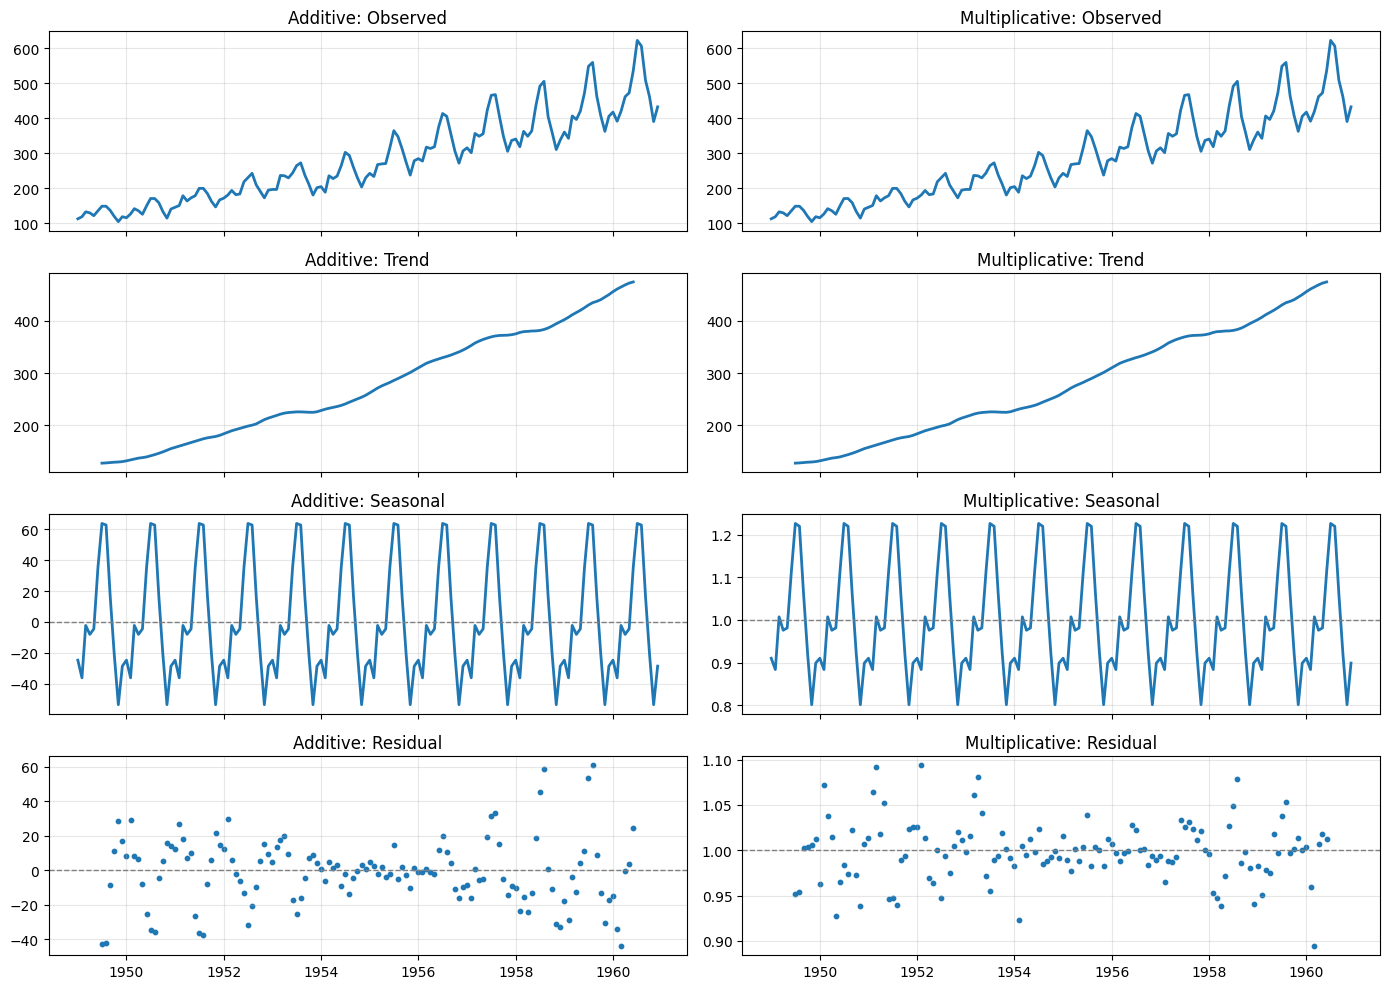

In [19]:
# Compare both models side by side:
# rows = parts of the series, columns = models
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)

models = [("Additive", decomp_add), ("Multiplicative", decomp_mul)]

for col, (name, decomp) in enumerate(models):
    parts = [
        ("Observed", decomp.observed),
        ("Trend", decomp.trend),
        ("Seasonal", decomp.seasonal),
        ("Residual", decomp.resid),
    ]
    for row, (part_name, values) in enumerate(parts):
        ax = axes[row, col]
        if part_name == "Residual":
            # Residuals are separate points, so we show them as dots
            ax.scatter(values.index, values, s=10)
        else:
            ax.plot(values.index, values, linewidth=2)
        ax.set_title(f"{name}: {part_name}")
        ax.grid(alpha=0.3)

# Reference lines: "no effect" is 0 for additive and 1 for multiplicative
for row in (2, 3):
    axes[row, 0].axhline(0, color="gray", linestyle="--", linewidth=1)
    axes[row, 1].axhline(1, color="gray", linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

In [20]:
# Which model is better? Look at the residuals.
# Good residuals = random noise. They should NOT repeat the seasonal pattern.
# Check: correlation between residual and seasonal part, in three periods.
# Close to 0 = seasonality is fully captured.
# Far from 0 = the model gets the size of the seasonal swings wrong.
periods = [(1949, 1952), (1953, 1956), (1957, 1960)]

rows = []
for start, end in periods:
    row = {"period": f"{start}-{end}"}
    for name, decomp in models:
        resid = decomp.resid.dropna()
        seasonal = decomp.seasonal[resid.index]
        in_period = (resid.index.year >= start) & (resid.index.year <= end)
        row[name] = resid[in_period].corr(seasonal[in_period])
    rows.append(row)

resid_vs_seasonal = pd.DataFrame(rows).set_index("period")
resid_vs_seasonal.round(2)

,Additive,Multiplicative
period,,
1949-1952,-0.95,-0.47
1953-1956,-0.10,0.08
1957-1960,0.90,0.54


In [21]:
# Size of the residuals in % of the trend (smaller = the model explains more).
# Additive residuals are in thousands, so we divide them by the trend.
# Multiplicative residuals are ratios around 1, so we subtract 1.
resid_pct = pd.Series({
    "Additive": (decomp_add.resid / decomp_add.trend).abs().mean() * 100,
    "Multiplicative": (decomp_mul.resid - 1).abs().mean() * 100,
})

resid_pct.round(1)

Additive          6.1
Multiplicative    2.4
dtype: float64

## 8. Variance and transformations

- Do the seasonal swings get bigger as the level grows?
- Log / Box-Cox transformation

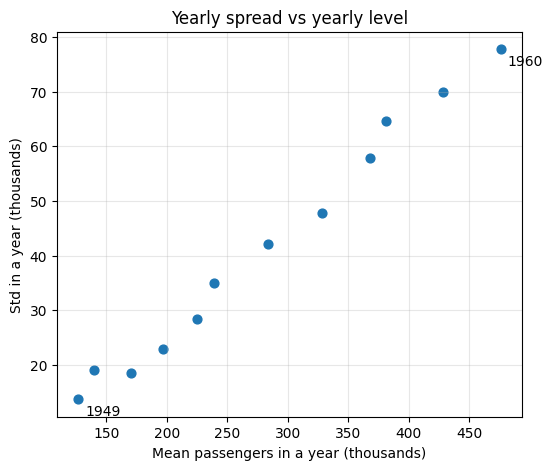

Correlation (mean vs std): 0.99


In [22]:
# Does the spread grow together with the level?
# Each dot = one year: average level (x) vs size of the ups and downs (y).
# We use the "yearly" table from section 5.
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(yearly["mean"], yearly["std"], s=40)

# Label the first and the last year
for year in [yearly.index[0], yearly.index[-1]]:
    ax.annotate(year, (yearly.loc[year, "mean"], yearly.loc[year, "std"]),
                textcoords="offset points", xytext=(5, -12))

ax.set_title("Yearly spread vs yearly level")
ax.set_xlabel("Mean passengers in a year (thousands)")
ax.set_ylabel("Std in a year (thousands)")
ax.grid(alpha=0.3)
plt.show()

# Correlation close to 1 = the spread grows in proportion to the level
print("Correlation (mean vs std):", round(yearly["mean"].corr(yearly["std"]), 2))

In [23]:
from scipy.stats import boxcox

# Log transformation: turns "x times bigger" into "+ a constant".
# So swings that grow with the level become the same size.
log_passengers = np.log(df["passengers"])

# Box-Cox finds the best power for the data automatically:
# lambda = 1 -> no change, lambda = 0 -> log, lambda = 0.5 -> square root
boxcox_values, boxcox_lambda = boxcox(df["passengers"])
boxcox_passengers = pd.Series(boxcox_values, index=df.index)

print("Box-Cox lambda:", round(boxcox_lambda, 3))

Box-Cox lambda: 0.148


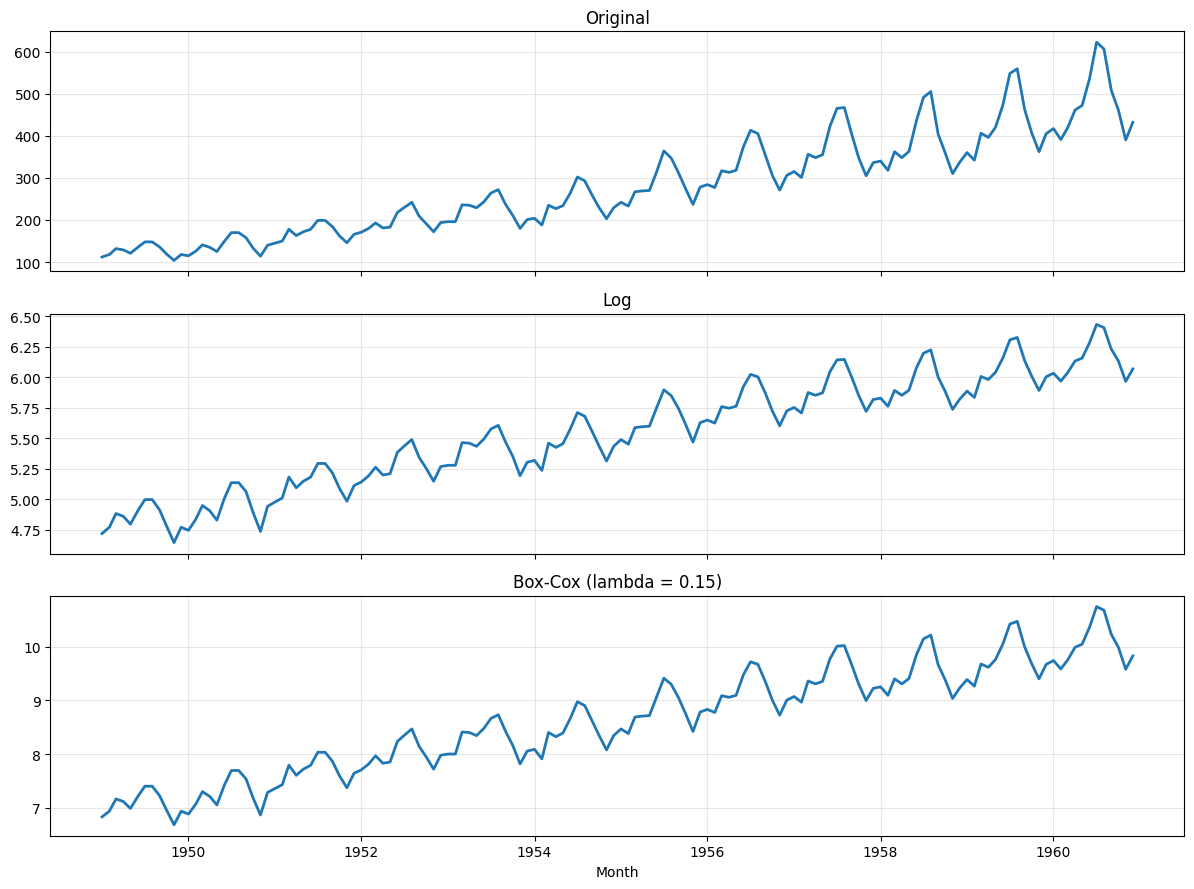

In [24]:
# Original, log and Box-Cox series one under another
series_to_plot = [
    ("Original", df["passengers"]),
    ("Log", log_passengers),
    (f"Box-Cox (lambda = {boxcox_lambda:.2f})", boxcox_passengers),
]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (name, values) in zip(axes, series_to_plot):
    ax.plot(values.index, values, linewidth=2)
    ax.set_title(name)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Month")

plt.tight_layout()
plt.show()

In [25]:
# Did it work? The std inside each year should now stay about the same.
spread_by_year = pd.DataFrame({
    "original": df["passengers"].groupby(df.index.year).std(),
    "log": log_passengers.groupby(df.index.year).std(),
    "boxcox": boxcox_passengers.groupby(df.index.year).std(),
})

# How many times the spread changed from the first year to the last year.
# Close to 1 = stable spread (good).
print("Last year / first year:")
print((spread_by_year.iloc[-1] / spread_by_year.iloc[0]).round(2))

spread_by_year.round(3)

Last year / first year:
original    5.67
log         1.44
boxcox      1.77
dtype: float64


,original,log,boxcox
month,,,
1949,13.720,0.108,0.222
1950,19.071,0.135,0.281
1951,18.438,0.108,0.231
1952,22.966,0.113,0.248
1953,28.467,0.127,0.284
1954,34.924,0.144,0.324
1955,42.140,0.144,0.334
1956,47.862,0.141,0.335
1957,57.891,0.152,0.366


## 9. Stationarity

- ADF and KPSS tests
- Differencing: regular and seasonal (lag 12)
- Check again after the transformations

In [26]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

# KPSS returns p-values only between 0.01 and 0.1.
# Outside this range it shows a warning and returns the edge value
# (0.01 means "0.01 or less", 0.1 means "0.1 or more"). We hide this warning.
warnings.simplefilter("ignore", InterpolationWarning)


def check_stationarity(series):
    """Run ADF and KPSS tests and return p-values and a short verdict."""
    series = series.dropna()

    # ADF: H0 = NOT stationary. p < 0.05 -> stationary
    adf_p = adfuller(series, autolag="AIC")[1]

    # KPSS: H0 = stationary. p < 0.05 -> NOT stationary
    kpss_p = kpss(series, regression="c", nlags="auto")[1]

    adf_ok = adf_p < 0.05
    kpss_ok = kpss_p >= 0.05
    if adf_ok and kpss_ok:
        verdict = "stationary"
    elif not adf_ok and not kpss_ok:
        verdict = "NOT stationary"
    else:
        verdict = "tests disagree"

    return {"ADF p-value": round(adf_p, 4), "KPSS p-value": round(kpss_p, 4), "verdict": verdict}

In [27]:
# Differencing = "change compared to some earlier month"
# diff(1)  -> change from the previous month (removes the trend)
# diff(12) -> change from the same month last year (removes the seasonality)
log_diff_1 = log_passengers.diff(1)
log_diff_12 = log_passengers.diff(12)
log_diff_1_12 = log_passengers.diff(12).diff(1)  # both

variants = {
    "original": df["passengers"],
    "log": log_passengers,
    "log, diff(1)": log_diff_1,
    "log, diff(12)": log_diff_12,
    "log, diff(12) + diff(1)": log_diff_1_12,
}

# Run both tests for each variant
stationarity = pd.DataFrame({name: check_stationarity(s) for name, s in variants.items()}).T
stationarity

,ADF p-value,KPSS p-value,verdict
original,0.9919,0.01,NOT stationary
log,0.4224,0.01,NOT stationary
"log, diff(1)",0.0711,0.1,tests disagree
"log, diff(12)",0.0724,0.1,tests disagree
"log, diff(12) + diff(1)",0.0002,0.1,stationary


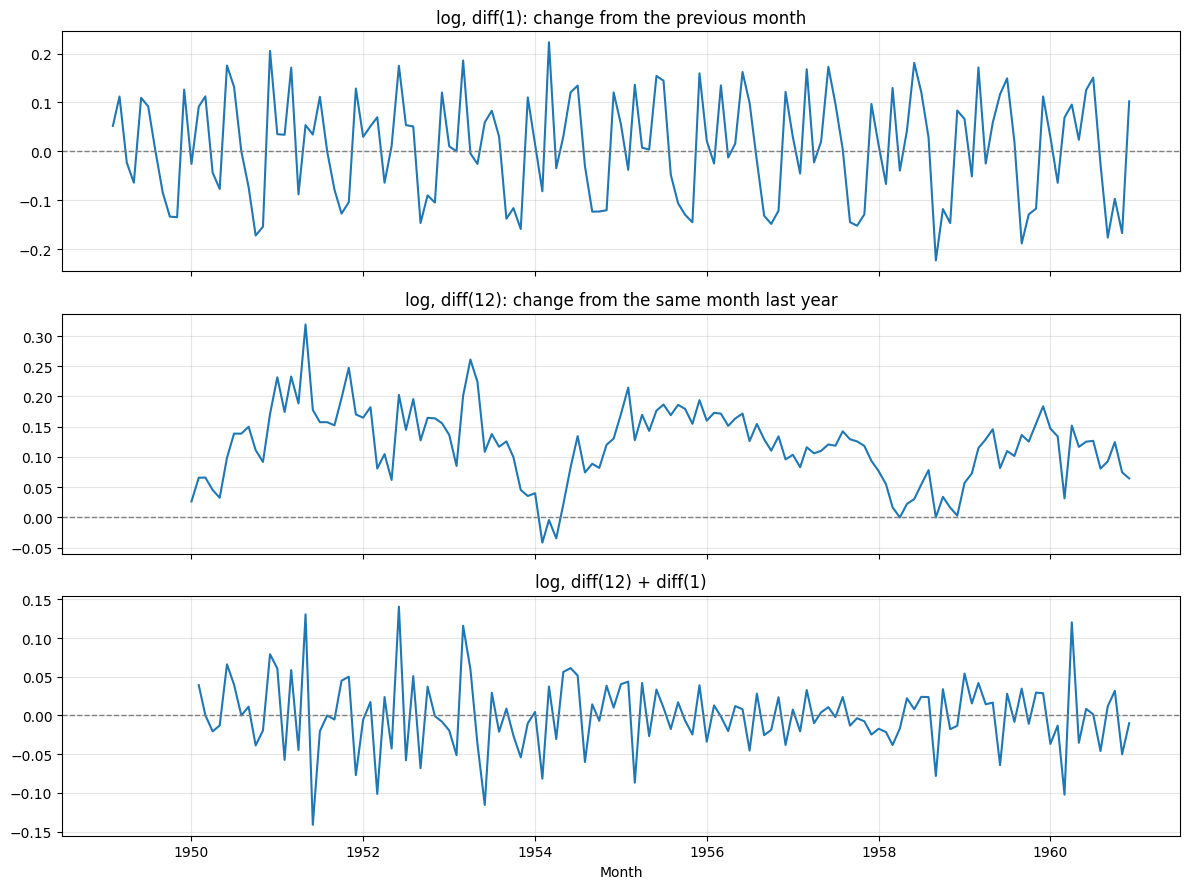

In [28]:
# Plot the differenced series: a stationary series moves around a flat line
# with the same spread over the whole period
diff_to_plot = [
    ("log, diff(1): change from the previous month", log_diff_1),
    ("log, diff(12): change from the same month last year", log_diff_12),
    ("log, diff(12) + diff(1)", log_diff_1_12),
]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (name, values) in zip(axes, diff_to_plot):
    ax.plot(values.index, values, linewidth=1.5)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(name)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Month")

plt.tight_layout()
plt.show()

## 10. Autocorrelation

ACF and PACF plots for the original and transformed series.

In [29]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# How many lags (months back) to show: 3 full years
n_lags = 36


def plot_acf_pacf(series, title):
    """ACF on the left, PACF on the right. Blue area = 95% confidence band."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(series.dropna(), lags=n_lags, ax=ax1)
    plot_pacf(series.dropna(), lags=n_lags, ax=ax2, method="ywm")

    for ax, name in [(ax1, "ACF"), (ax2, "PACF")]:
        ax.set_title(f"{name}: {title}")
        ax.set_xlabel("Lag (months)")
        ax.set_xticks(range(0, n_lags + 1, 6))  # ticks every 6 months
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

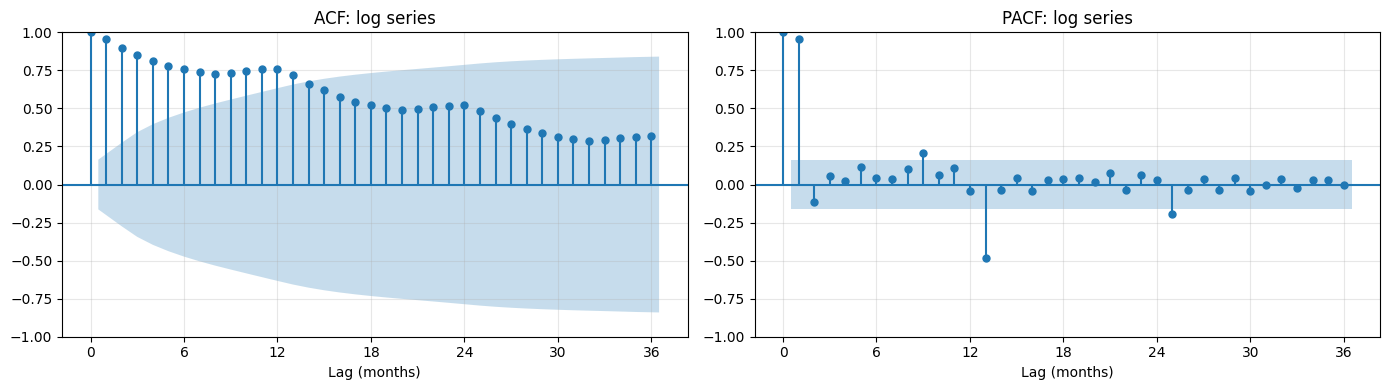

In [30]:
# Before differencing: log series (has trend and seasonality)
plot_acf_pacf(log_passengers, "log series")

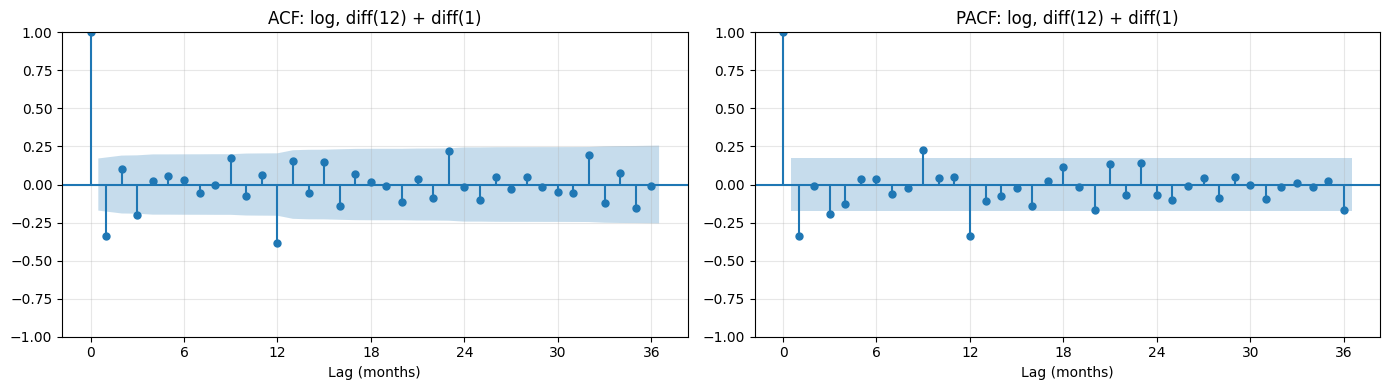

In [31]:
# After differencing: stationary series from section 9
plot_acf_pacf(log_diff_1_12, "log, diff(12) + diff(1)")

In [32]:
from statsmodels.tsa.stattools import acf, pacf

# The same in numbers: which lags go outside the 95% band?
# For a long series the band is about +-1.96 / sqrt(n)
stationary = log_diff_1_12.dropna()
bound = 1.96 / np.sqrt(len(stationary))

acf_values = acf(stationary, nlags=n_lags)
pacf_values = pacf(stationary, nlags=n_lags, method="ywm")

# Skip lag 0 (it is always 1)
significant = pd.DataFrame({"ACF": acf_values, "PACF": pacf_values}).iloc[1:]
significant = significant[(significant.abs() > bound).any(axis=1)]

print("95% bound: +-", round(bound, 3))
significant.round(3)

95% bound: +- 0.171


,ACF,PACF
1,-0.341,-0.341
3,-0.202,-0.193
9,0.176,0.226
12,-0.387,-0.339
23,0.223,0.143
32,0.196,-0.015


## 11. Conclusions

**Data**
- 144 monthly values from January 1949 to December 1960.
- No missing values, no missing months, no duplicates, no clear outliers.

**Trend**
- Strong upward trend: the 12-month rolling mean grows from about 125k to 475k passengers (about 3.8 times).
- Yearly totals grow every year, by 3–22% per year.

**Seasonality**
- Stable yearly pattern with a period of 12 months.
- Peak in July–August (about 23% above the trend), lowest month is November (about 20% below the trend).
- Seasonal swings grow together with the level, so seasonality is **multiplicative**:
  multiplicative decomposition leaves 2.4% residuals vs 6.1% for additive.
- The seasonal pattern gets a little stronger over time, so some seasonality stays in the residuals.

**Transformations**
- The spread is proportional to the level (correlation 0.99), so we use a **log transformation**.
  Log stabilizes the spread better than Box-Cox (lambda ≈ 0.15).
- The series is **stationary after log + diff(12) + diff(1)**: ADF p < 0.001, KPSS p ≥ 0.1.

**Autocorrelation**
- After differencing, ACF has clear spikes only at lag 1 and lag 12, then cuts off.
- This points to a non-seasonal MA(1) and a seasonal MA(1).

**Candidate models**
- Main: **SARIMA(0,1,1)(0,1,1,12)** on the log series (the classic "airline model").
- Alternative: SARIMA(1,1,0)(1,1,0,12).
- Also worth comparing: Holt-Winters with multiplicative seasonality.
- Forecasts made on the log scale must be converted back with `np.exp()`.

**Next steps**
- Split the data by time: last 12–24 months as the test set.
- Use a simple baseline: seasonal naive (value from the same month last year).
- Compare models by AIC and test error (MAPE, RMSE).
- Check model residuals: they should be white noise (Ljung-Box test).